In [174]:
# Amazon prime priject

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# from wordcloud import wordcloud ,STOPWORKS ,ImageColorGenerator
import warnings
warnings.filterwarnings("ignore")

In [6]:
data=pd.read_csv("amazon_prime_titles.xls")

In [7]:
data.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,"March 30, 2021",2014,NaN,113 min,"Comedy, Drama",A small fishing village must procure a local d...
1,s2,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,"March 30, 2021",2018,13+,110 min,"Drama, International",A Metro Family decides to fight a Cyber Crimin...
2,s3,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,"March 30, 2021",2017,NaN,74 min,"Action, Drama, Suspense",After a man discovers his wife is cheating on ...
3,s4,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,"March 30, 2021",2014,NaN,69 min,Documentary,"Pink breaks the mold once again, bringing her ..."
4,s5,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,"March 30, 2021",1989,NaN,45 min,"Drama, Fantasy",Teenage Matt Banting wants to work with a famo...


In [8]:
data.drop(["show_id"],axis=1,inplace=True)       # axis=1 for coloumn axis=0 for rows
data.drop(["description"],axis=1,inplace=True)

In [9]:
data.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in
0,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,"March 30, 2021",2014,NaN,113 min,"Comedy, Drama"
1,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,"March 30, 2021",2018,13+,110 min,"Drama, International"
2,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,"March 30, 2021",2017,NaN,74 min,"Action, Drama, Suspense"
3,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,"March 30, 2021",2014,NaN,69 min,Documentary
4,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,"March 30, 2021",1989,NaN,45 min,"Drama, Fantasy"


In [180]:
# Checking for duplicate 
data.duplicated().sum() # remove duplicate

0

In [181]:
data.describe() #they show numberical column stats

,release_year
count,9668.000000
mean,2008.341849
std,18.922482
min,1920.000000
25%,2007.000000
50%,2016.000000
75%,2019.000000
max,2021.000000


In [182]:
data.info()  # data.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9668 entries, 0 to 9667
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   type          9668 non-null   object
 1   title         9668 non-null   object
 2   director      7585 non-null   object
 3   cast          8435 non-null   object
 4   country       672 non-null    object
 5   date_added    155 non-null    object
 6   release_year  9668 non-null   int64 
 7   rating        9331 non-null   object
 8   duration      9668 non-null   object
 9   listed_in     9668 non-null   object
dtypes: int64(1), object(9)
memory usage: 755.4+ KB


In [183]:
data.dtypes

type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
dtype: object

In [184]:
data.isna().sum () #data.isnull().sum()

type               0
title              0
director        2083
cast            1233
country         8996
date_added      9513
release_year       0
rating           337
duration           0
listed_in          0
dtype: int64

In [185]:
#FIlling the null values
data["director"].fillna("unavailable",inplace=True)
data["cast"].fillna("unavailable",inplace=True)
data["country"].fillna("unavailable",inplace=True)
data["date_added"]=data["date_added"].ffill()
data["rating"]=data["rating"].fillna(data["rating"].mode()[0])

In [186]:
data.isna().sum()

type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [187]:
data["date_added"]=pd.to_datetime(data["date_added"]) # If you see the date in data first change in datetime by using to_datetime

In [188]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9668 entries, 0 to 9667
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   type          9668 non-null   object        
 1   title         9668 non-null   object        
 2   director      9668 non-null   object        
 3   cast          9668 non-null   object        
 4   country       9668 non-null   object        
 5   date_added    9668 non-null   datetime64[ns]
 6   release_year  9668 non-null   int64         
 7   rating        9668 non-null   object        
 8   duration      9668 non-null   object        
 9   listed_in     9668 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(8)
memory usage: 755.4+ KB


In [189]:
# top 10 directors with directed movies
filtered_directors=data[data["director"]!="unavailable"]
top_directors=filtered_directors["director"].value_counts()[:10]

In [190]:
top_directors

director
Mark Knight              113
Cannis Holder             61
Moonbug Entertainment     37
Jay Chapman               34
Arthur van Merwijk        30
Manny Rodriguez           22
John English              20
1                         16
Brian Volk-Weiss          15
Baeble Music              14
Name: count, dtype: int64

<Axes: ylabel='director'>

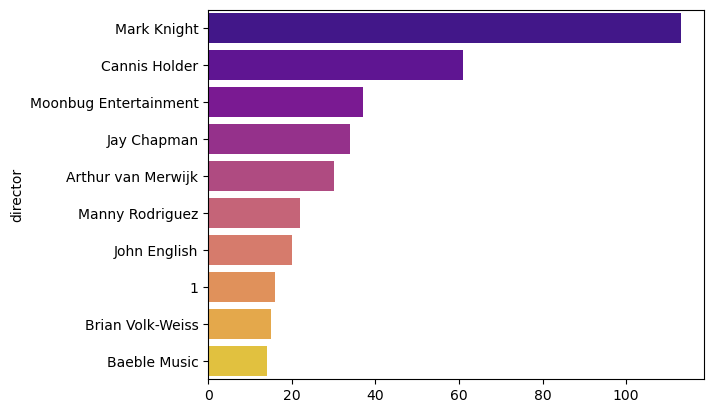

In [191]:
# plasma means color
sns.barplot(x=top_directors.values,y=top_directors.index,palette="plasma")

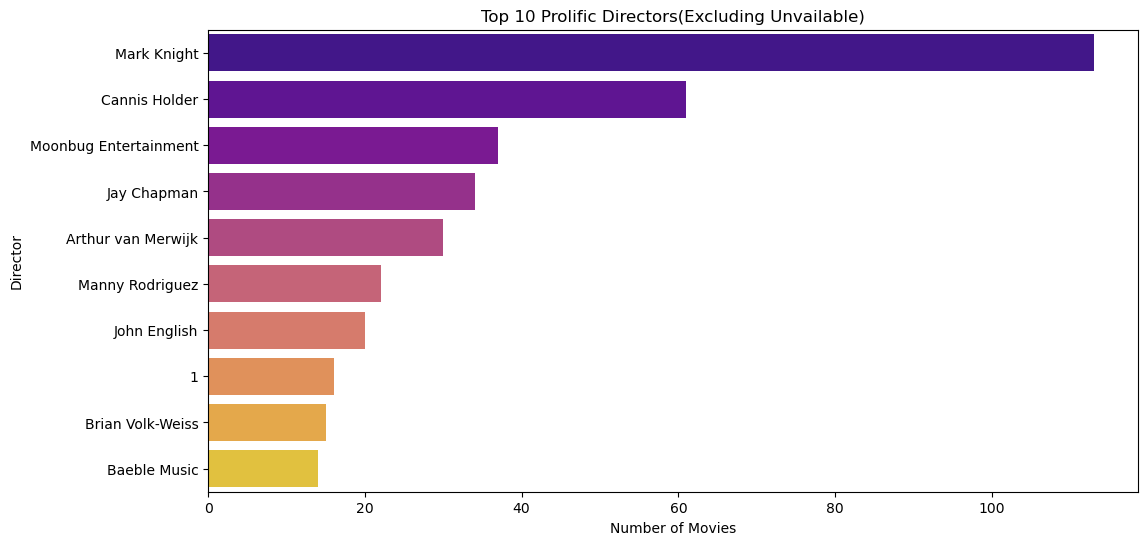

In [192]:
plt.figure(figsize=(12,6))
sns.barplot(x=top_directors.values,y=top_directors.index,palette="plasma")    # plasma means color
plt.title("Top 10 Prolific Directors(Excluding Unvailable)")
plt.xlabel("Number of Movies")
plt.ylabel("Director")
plt.show()

In [193]:
filtered_actors=data[data["cast"]!="unavailable"]
top_actors=filtered_actors["cast"].value_counts().head()

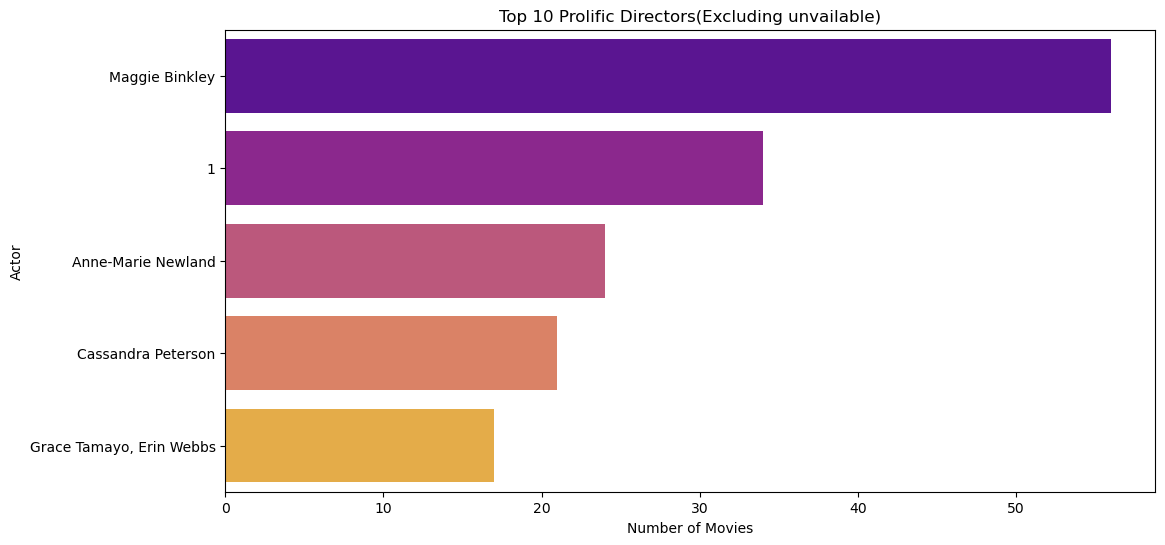

In [194]:
plt.figure(figsize=(12,6))
sns.barplot(x=top_actors.values,y=top_actors.index,palette="plasma")    # plasma means color
plt.title("Top 10 Prolific Directors(Excluding unvailable)")
plt.xlabel("Number of Movies")
plt.ylabel("Actor")
plt.show()

In [195]:
data["type"].value_counts()

type
Movie      7814
TV Show    1854
Name: count, dtype: int64

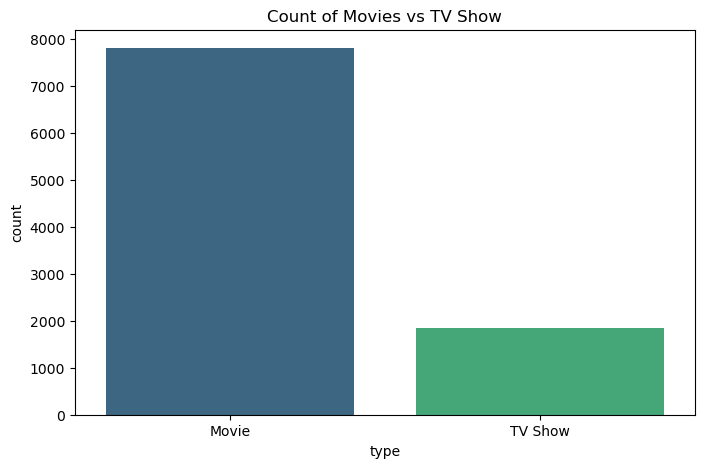

In [196]:
# Count of each content type(Movievs.TV Show)
plt.figure(figsize=(8,5))
sns.countplot(data=data, x="type", palette="viridis")
plt.title("Count of Movies vs TV Show")
plt.show()

<Axes: ylabel='count'>

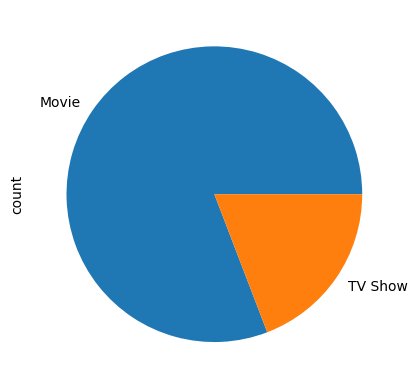

In [197]:
data["type"].value_counts().plot(kind="pie")

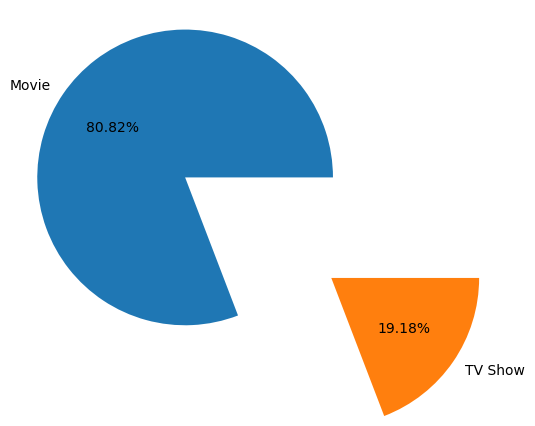

In [198]:
plt.pie(data["type"].value_counts(),labels=data["type"].value_counts().index,autopct="%1.2f%%",explode=[0.2,1])
plt.show()

In [199]:
data["rating"].unique() 

array(['13+', 'ALL', '18+', 'R', 'TV-Y', 'TV-Y7', 'NR', '16+', 'TV-PG',
       '7+', 'TV-14', 'TV-NR', 'TV-G', 'PG-13', 'TV-MA', 'G', 'PG',
       'NC-17', 'UNRATED', '16', 'AGES_16_', 'AGES_18_', 'ALL_AGES',
       'NOT_RATE'], dtype=object)

In [200]:
data.groupby("type")["rating"].value_counts()

type     rating  
Movie    13+         2180
         16+         1272
         18+         1097
         R           1010
         ALL          988
         PG-13        393
         7+           288
         PG           253
         NR           194
         G             93
         UNRATED       33
         AGES_18_       3
         NC-17          3
         NOT_RATE       3
         AGES_16_       2
         16             1
         ALL_AGES       1
TV Show  ALL          280
         16+          275
         13+          274
         TV-14        208
         TV-PG        169
         18+          146
         TV-NR        105
         7+            97
         TV-G          81
         TV-MA         77
         TV-Y          74
         TV-Y7         39
         NR            29
Name: count, dtype: int64

<Axes: xlabel='rating', ylabel='count'>

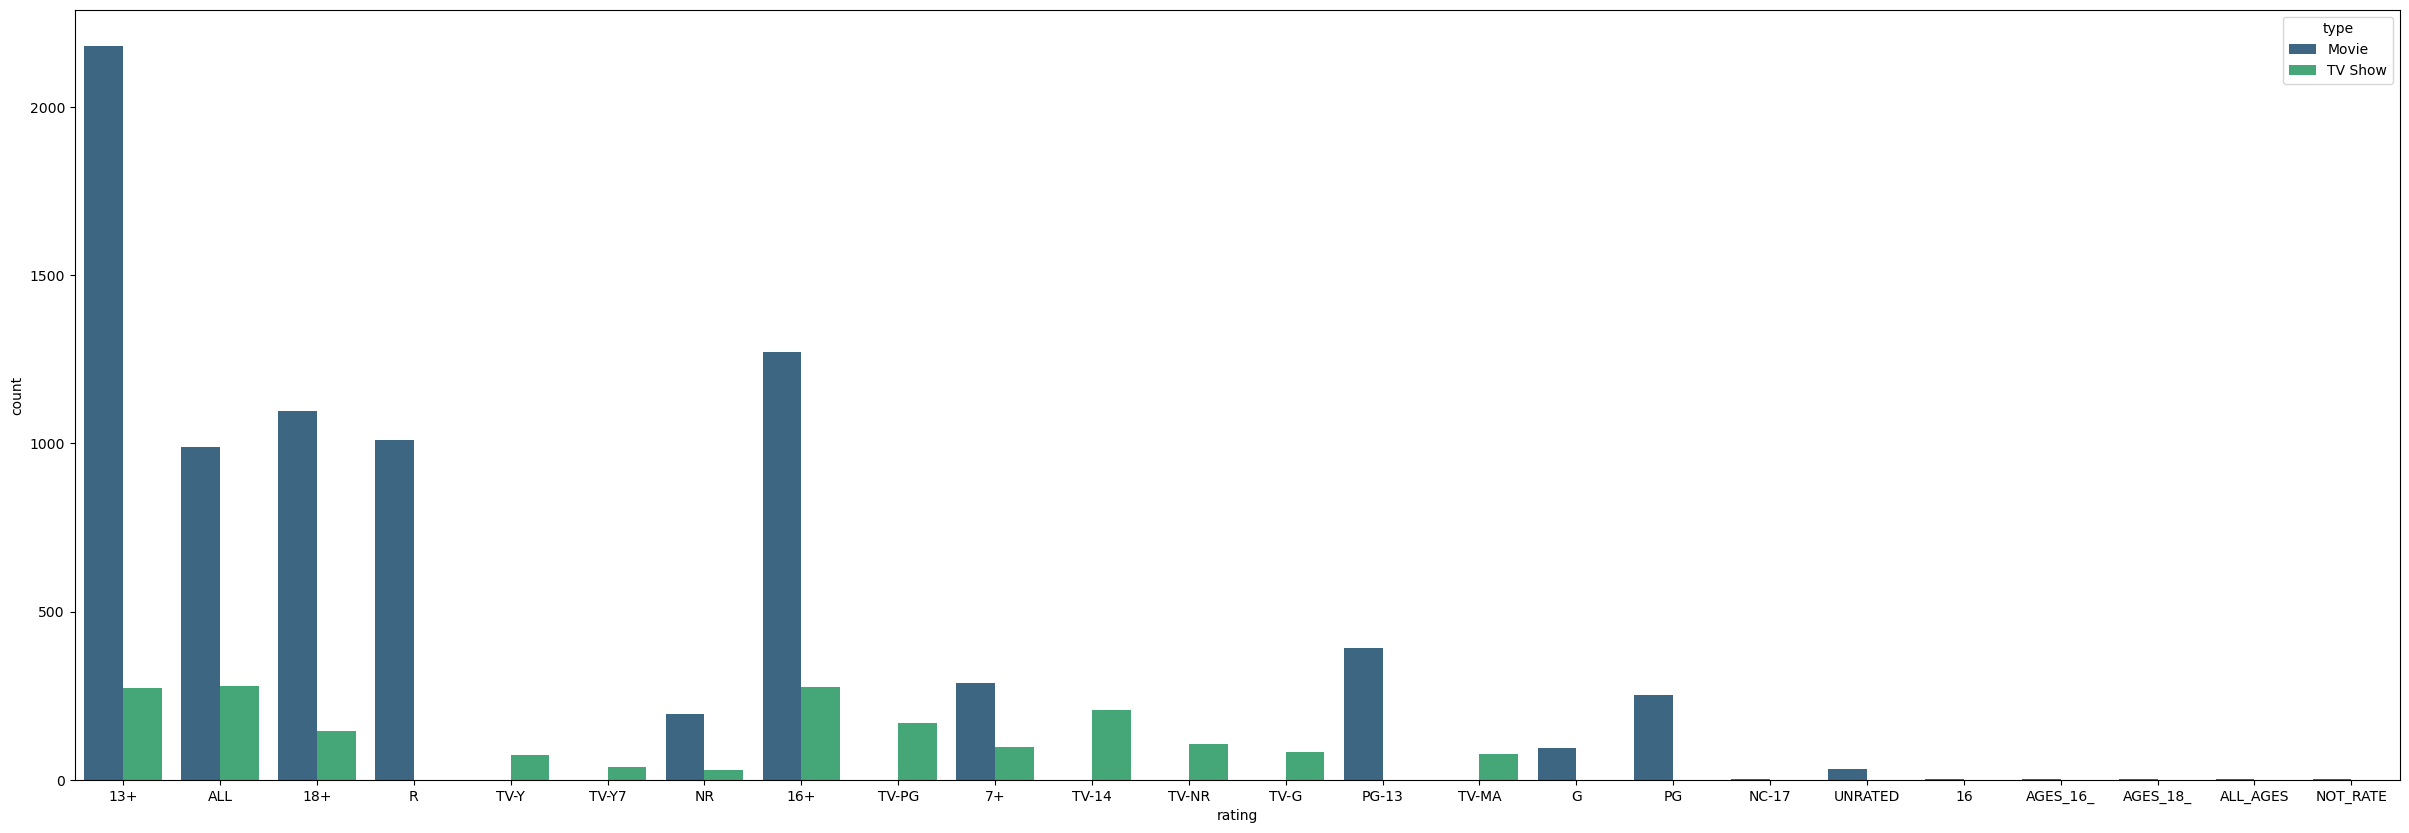

In [201]:
plt.figure(figsize=(30,10))
sns.countplot(x=data["rating"],data=data,hue="type",palette="viridis")

In [202]:
# Calculating the number of titles per country
filtered_country = data[data["country"] !="unavailable"]
country_counts=filtered_country["country"].value_counts()

In [203]:
country_counts

country
United States                            253
India                                    229
United Kingdom                            28
Canada                                    16
United Kingdom, United States             12
                                        ... 
United States, Germany, Brazil, Italy      1
South Africa                               1
Australia, United States, Germany          1
Germany, Austria, United States            1
Italy, Spain                               1
Name: count, Length: 86, dtype: int64

In [204]:
top_countries= country_counts.nlargest(3).index

In [205]:
top_countries

Index(['United States', 'India', 'United Kingdom'], dtype='object', name='country')

In [206]:
df_top_countries=filtered_country[filtered_country["country"].isin(top_countries)]
df_top_countries

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in
1,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,2021-03-30,2018,13+,110 min,"Drama, International"
2,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,2021-03-30,2017,13+,74 min,"Action, Drama, Suspense"
3,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,2021-03-30,2014,13+,69 min,Documentary
4,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,2021-03-30,1989,13+,45 min,"Drama, Fantasy"
5,Movie,Living With Dinosaurs,Paul Weiland,"Gregory Chisholm, Juliet Stevenson, Brian Hens...",United Kingdom,2021-03-30,1989,13+,52 min,"Fantasy, Kids"
...,...,...,...,...,...,...,...,...,...,...
9604,Movie,Bride Wars,Gary Winick,"Kate Hudson, Anne Hathaway, Kristen Johnston, ...",United States,2021-10-08,2009,PG,89 min,Comedy
9614,Movie,What Happens in Vegas,Tom Vaughan,"Cameron Diaz, Ashton Kutcher, Rob Corddry, ...",United States,2021-10-08,2008,PG-13,99 min,Comedy
9641,Movie,Marley & Me,David Frankel,"Owen Wilson, Jennifer Aniston",United States,2021-10-10,2008,PG,116 min,"Comedy, Drama, Kids"
9643,Movie,Love & Other Drugs,Edward Zwick,"K K, Jake Gyllenhaal, Anne Hathaway, Oliver Pl...",United States,2021-10-10,2010,R,112 min,"Comedy, Drama"


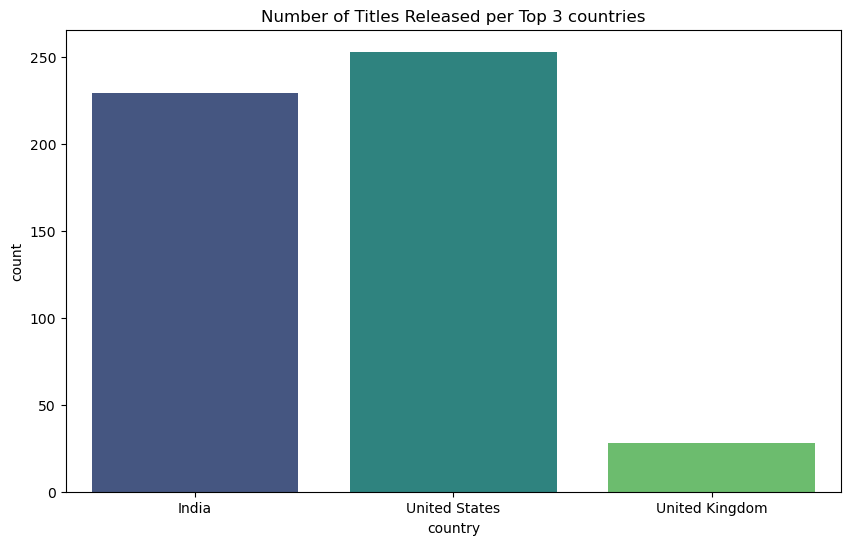

In [207]:
# plotting the number of titles released per top 3 countries
plt.figure(figsize=(10,6))
sns.countplot(data=df_top_countries,x="country",palette="viridis")
plt.title("Number of Titles Released per Top 3 countries")
plt.show()

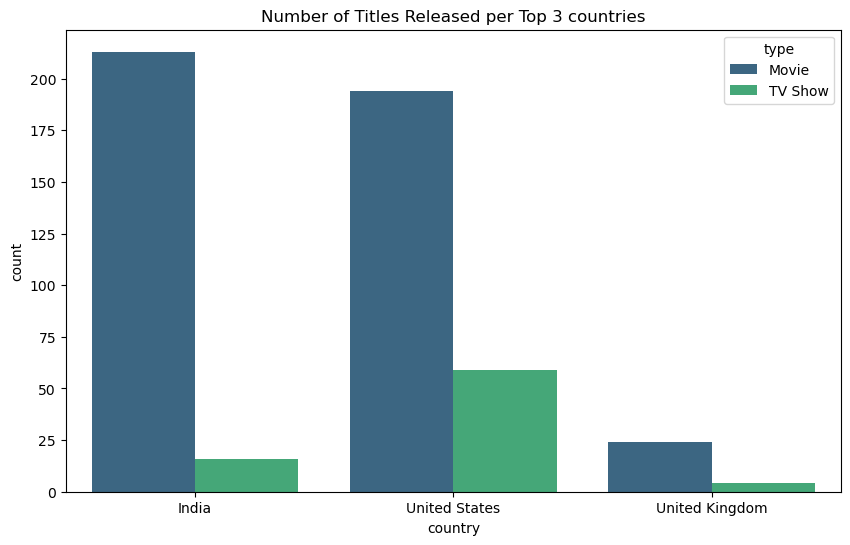

In [208]:
filtered_country = data[data["country"] !="unavailable"]
country_counts=filtered_country["country"].value_counts()

top_countries= country_counts.nlargest(3).index

df_top_countries=filtered_country[filtered_country["country"].isin(top_countries)]
df_top_countries

plt.figure(figsize=(10,6))
sns.countplot(data=df_top_countries,x="country",hue="type",palette="viridis")
plt.title("Number of Titles Released per Top 3 countries")
plt.show()

In [209]:
year_counts=data["release_year"].value_counts()
year_counts

release_year
2021    1442
2020     962
2019     929
2018     623
2017     562
        ... 
1922       2
1926       2
1924       1
1923       1
1927       1
Name: count, Length: 100, dtype: int64

In [210]:
# Getting the top 10 release_year

top_years=year_counts.nlargest(10).index
top_years

Index([2021, 2020, 2019, 2018, 2017, 2016, 2014, 2015, 2013, 2011], dtype='int64', name='release_year')

In [211]:
# Filtering the DataFrame  to include only the top 10 years

df_top_years=data[data["release_year"].isin(top_years)]     # isin removed the or values 
df_top_years

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in
0,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,2021-03-30,2014,13+,113 min,"Comedy, Drama"
1,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,2021-03-30,2018,13+,110 min,"Drama, International"
2,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,2021-03-30,2017,13+,74 min,"Action, Drama, Suspense"
3,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,2021-03-30,2014,13+,69 min,Documentary
6,Movie,Hired Gun,Fran Strine,"Alice Cooper, Liberty DeVitto, Ray Parker Jr.,...",United States,2021-03-30,2017,13+,98 min,"Documentary, Special Interest"
...,...,...,...,...,...,...,...,...,...,...
9658,Movie,12 Dates of Christmas,unavailable,unavailable,unavailable,2021-10-10,2011,PG,87 min,"Drama, Romance"
9660,Movie,The Man in the Hat,"John-Paul Davidson, Stephen Warbeck","Ciaran Hinds, Stephen Dillane, Maïwenn",unavailable,2021-10-10,2021,13+,96 min,Comedy
9662,Movie,River,Emily Skye,"Mary Cameron Rogers, Alexandra Rose, Rob Marsh...",unavailable,2021-10-10,2021,16+,93 min,"Drama, Science Fiction, Suspense"
9664,TV Show,Planet Patrol,unavailable,"DICK VOSBURGH, RONNIE STEVENS, LIBBY MORRIS, M...",unavailable,2021-10-10,2018,13+,4 Seasons,TV Shows


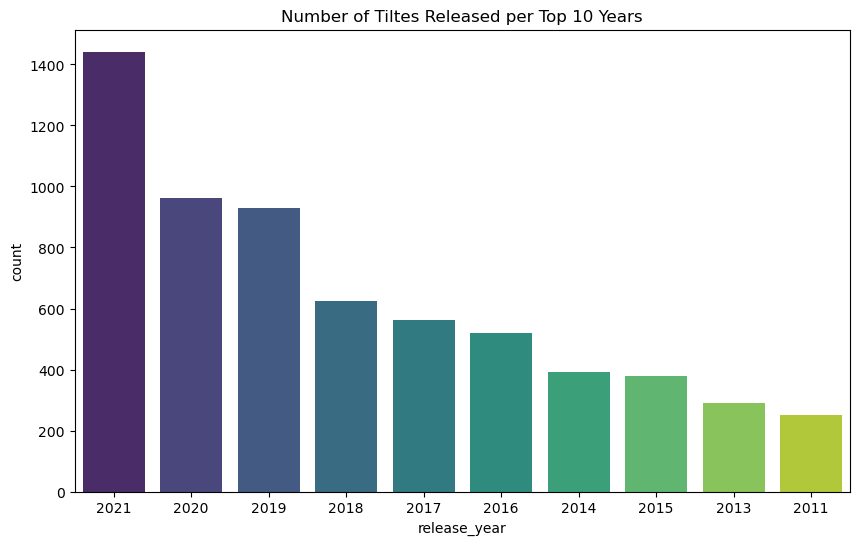

In [212]:
# PLotting the number of titles released per top 10 years

plt.figure(figsize=(10,6))
sns.countplot(data=df_top_years, x="release_year", palette="viridis", order=top_years)
plt.title("Number of Tiltes Released per Top 10 Years")
plt.show()
              

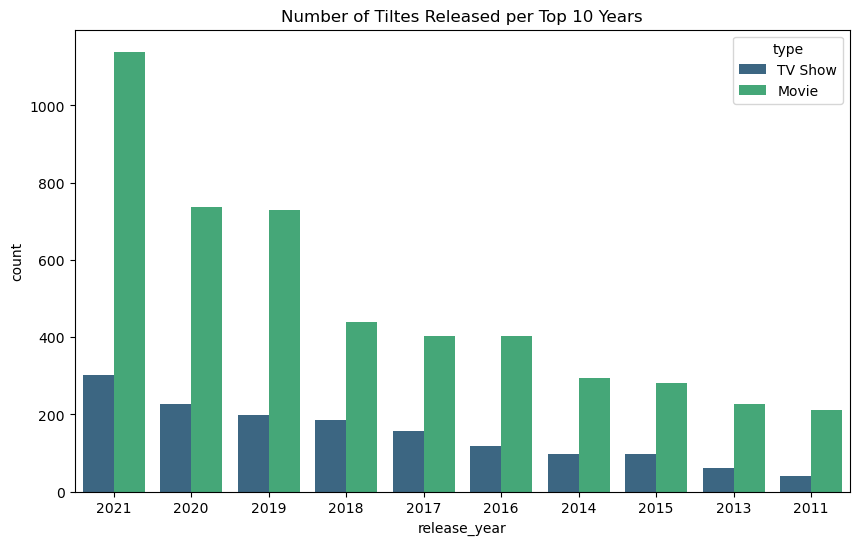

In [213]:
year_counts=data["release_year"].value_counts()

top_years=year_counts.nlargest(10).index

df_top_years=data[data["release_year"].isin(top_years)]

plt.figure(figsize=(10,6))
sns.countplot(data=df_top_years, x="release_year",hue="type", palette="viridis", order=top_years)
plt.title("Number of Tiltes Released per Top 10 Years")
plt.show()
              

In [214]:
# Distribution of genres
# splitting the genres
data["Genres"]=data["listed_in"].apply(lambda x: x.split(', '))
data["Genres"]

0                 [Comedy, Drama]
1          [Drama, International]
2       [Action, Drama, Suspense]
3                   [Documentary]
4                [Drama, Fantasy]
                  ...            
9663                     [Comedy]
9664                   [TV Shows]
9665                     [Action]
9666              [Drama, Sports]
9667    [Action, Drama, Suspense]
Name: Genres, Length: 9668, dtype: object

In [215]:
# Exploding the genres into seperate rows
genres_exploded=data.explode("Genres")
genres_exploded

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,Genres
0,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,2021-03-30,2014,13+,113 min,"Comedy, Drama",Comedy
0,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,2021-03-30,2014,13+,113 min,"Comedy, Drama",Drama
1,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,2021-03-30,2018,13+,110 min,"Drama, International",Drama
1,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,2021-03-30,2018,13+,110 min,"Drama, International",International
2,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,2021-03-30,2017,13+,74 min,"Action, Drama, Suspense",Action
...,...,...,...,...,...,...,...,...,...,...,...
9666,TV Show,Maradona: Blessed Dream,unavailable,"Esteban Recagno, Ezequiel Stremiz, Luciano Vit...",unavailable,2021-10-10,2021,TV-MA,1 Season,"Drama, Sports",Drama
9666,TV Show,Maradona: Blessed Dream,unavailable,"Esteban Recagno, Ezequiel Stremiz, Luciano Vit...",unavailable,2021-10-10,2021,TV-MA,1 Season,"Drama, Sports",Sports
9667,Movie,Harry Brown,Daniel Barber,"Michael Caine, Emily Mortimer, Joseph Gilgun, ...",unavailable,2021-10-10,2010,R,103 min,"Action, Drama, Suspense",Action
9667,Movie,Harry Brown,Daniel Barber,"Michael Caine, Emily Mortimer, Joseph Gilgun, ...",unavailable,2021-10-10,2010,R,103 min,"Action, Drama, Suspense",Drama


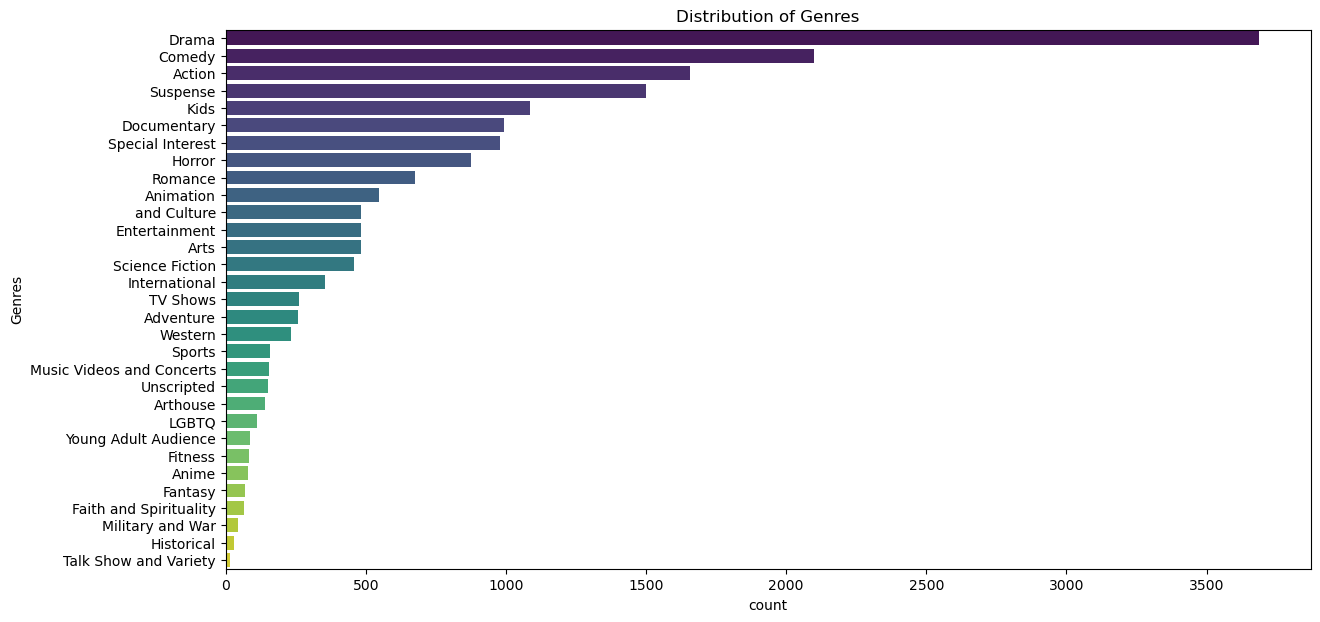

In [216]:
plt.figure(figsize=(14,7))
sns.countplot(data=genres_exploded,y="Genres",
              order=genres_exploded["Genres"].value_counts().index,
              palette="viridis")
plt.title("Distribution of Genres")
plt.show()

In [217]:
# Filter data for movies and TV shows separately
df_movies= data[data["type"]=="Movie"].copy()
df_tv_shows=data[data["type"]=="TV Show"].copy()

In [218]:
# Extract numeric duration for movies
df_movies["duration_num"]=df_movies["duration"].str.extract("(\d+)",expand=False).astype(float)  # 

In [219]:
df_movies

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,Genres,duration_num
0,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,2021-03-30,2014,13+,113 min,"Comedy, Drama","[Comedy, Drama]",113.0
1,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,2021-03-30,2018,13+,110 min,"Drama, International","[Drama, International]",110.0
2,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,2021-03-30,2017,13+,74 min,"Action, Drama, Suspense","[Action, Drama, Suspense]",74.0
3,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,2021-03-30,2014,13+,69 min,Documentary,[Documentary],69.0
4,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,2021-03-30,1989,13+,45 min,"Drama, Fantasy","[Drama, Fantasy]",45.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9660,Movie,The Man in the Hat,"John-Paul Davidson, Stephen Warbeck","Ciaran Hinds, Stephen Dillane, Maïwenn",unavailable,2021-10-10,2021,13+,96 min,Comedy,[Comedy],96.0
9662,Movie,River,Emily Skye,"Mary Cameron Rogers, Alexandra Rose, Rob Marsh...",unavailable,2021-10-10,2021,16+,93 min,"Drama, Science Fiction, Suspense","[Drama, Science Fiction, Suspense]",93.0
9663,Movie,Pride Of The Bowery,Joseph H. Lewis,"Leo Gorcey, Bobby Jordan",unavailable,2021-10-10,1940,7+,60 min,Comedy,[Comedy],60.0
9665,Movie,Outpost,Steve Barker,"Ray Stevenson, Julian Wadham, Richard Brake, M...",unavailable,2021-10-10,2008,R,90 min,Action,[Action],90.0


In [220]:
df_tv_shows["duration_num"]=df_movies["duration"].str.extract("(\d+)",expand=False).astype(float)  # 

In [221]:
df_tv_shows

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,Genres,duration_num
17,TV Show,Zoo Babies,unavailable,Narrator - Gillian Barlett,unavailable,2021-06-03,2008,ALL,1 Season,"Kids, Special Interest","[Kids, Special Interest]",NaN
18,TV Show,Zoë Coombs Marr: Bossy Bottom,unavailable,Zoë Coombs Marr,unavailable,2021-06-03,2020,18+,1 Season,"Comedy, Talk Show and Variety","[Comedy, Talk Show and Variety]",NaN
20,TV Show,Zoboomafoo,unavailable,unavailable,unavailable,2021-06-03,2001,TV-Y,1 Season,Kids,[Kids],NaN
21,TV Show,Zo Zo Zombie: Mini-Series,unavailable,"Alex Cazares, Ben Diskin, Cristina Vee, Erika ...",unavailable,2021-06-03,2020,TV-Y7,1 Season,"Action, Anime, Comedy","[Action, Anime, Comedy]",NaN
23,TV Show,ZeroZeroZero,unavailable,"ANDREA RISEBOROUGH, HAROLD TORRES, CLAUDIA PIN...",Italy,2021-06-03,2020,18+,1 Season,TV Shows,[TV Shows],NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
9651,TV Show,Glass Room,unavailable,"Elizaveta Maiskaya, Vsevolod Boldin, Alexander...",unavailable,2021-10-10,2019,16+,1 Season,Drama,[Drama],NaN
9655,TV Show,DaFUNdamentals Series,unavailable,"Emile Crawford, Randall Crawford, Jon Ward",unavailable,2021-10-10,2021,TV-Y,1 Season,"Animation, Kids","[Animation, Kids]",NaN
9661,TV Show,Terrahawks,unavailable,"DENISE BRYER, WINDSOR DAVIES, JEREMY HITCHEN, ...",unavailable,2021-10-10,1983,ALL,3 Seasons,TV Shows,[TV Shows],NaN
9664,TV Show,Planet Patrol,unavailable,"DICK VOSBURGH, RONNIE STEVENS, LIBBY MORRIS, M...",unavailable,2021-10-10,2018,13+,4 Seasons,TV Shows,[TV Shows],NaN


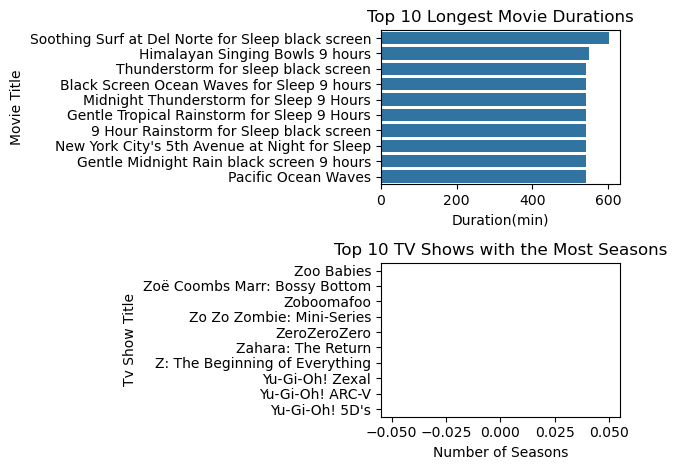

In [222]:
# Subplot 1: Top 10 Longest Movie Duration
plt.subplot(2,1,1)
sns.barplot(data=df_movies.sort_values(by="duration_num",ascending=False).head(10), y="title", x="duration_num",orient="horizontal")
plt.title("Top 10 Longest Movie Durations")
plt.xlabel("Duration(min)")
plt.ylabel("Movie Title")

# Subplot 2: Top 10 TV Shows with the Most Seasons

plt.subplot(2,1,2)
sns.barplot(data=df_tv_shows.sort_values(by="duration_num",ascending=False).head(10), y="title", x="duration_num",orient="horizontal")
plt.title("Top 10 TV Shows with the Most Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Tv Show Title")

plt.tight_layout()
plt.show()
        
        
                                    

In [223]:
data["type"].unique

<bound method Series.unique of 0         Movie
1         Movie
2         Movie
3         Movie
4         Movie
         ...   
9663      Movie
9664    TV Show
9665      Movie
9666    TV Show
9667      Movie
Name: type, Length: 9668, dtype: object>

In [224]:
df_tv_shows.sort_values(by="duration_num",ascending=False).head(10)

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,Genres,duration_num
17,TV Show,Zoo Babies,unavailable,Narrator - Gillian Barlett,unavailable,2021-06-03,2008,ALL,1 Season,"Kids, Special Interest","[Kids, Special Interest]",NaN
18,TV Show,Zoë Coombs Marr: Bossy Bottom,unavailable,Zoë Coombs Marr,unavailable,2021-06-03,2020,18+,1 Season,"Comedy, Talk Show and Variety","[Comedy, Talk Show and Variety]",NaN
20,TV Show,Zoboomafoo,unavailable,unavailable,unavailable,2021-06-03,2001,TV-Y,1 Season,Kids,[Kids],NaN
21,TV Show,Zo Zo Zombie: Mini-Series,unavailable,"Alex Cazares, Ben Diskin, Cristina Vee, Erika ...",unavailable,2021-06-03,2020,TV-Y7,1 Season,"Action, Anime, Comedy","[Action, Anime, Comedy]",NaN
23,TV Show,ZeroZeroZero,unavailable,"ANDREA RISEBOROUGH, HAROLD TORRES, CLAUDIA PIN...",Italy,2021-06-03,2020,18+,1 Season,TV Shows,[TV Shows],NaN
26,TV Show,Zahara: The Return,unavailable,"Natasha Heschélle, Curtis Morgan, Hannah Scott...",unavailable,2021-06-03,2020,16+,1 Season,TV Shows,[TV Shows],NaN
27,TV Show,Z: The Beginning of Everything,unavailable,"Christina Ricci , David Hoflin",United States,2021-06-03,2017,18+,1 Season,"Comedy, Drama","[Comedy, Drama]",NaN
28,TV Show,Yu-Gi-Oh! Zexal,unavailable,"Eli Jay, Marc Thompson, Sean Schemmel, Eileen ...",unavailable,2021-06-03,2015,TV-Y7,3 Seasons,"Animation, Anime, Fantasy","[Animation, Anime, Fantasy]",NaN
29,TV Show,Yu-Gi-Oh! ARC-V,unavailable,"Michael Liscio Jr., Emily Bauer",unavailable,2021-06-03,2018,TV-Y7,3 Seasons,"Action, Adventure, Animation","[Action, Adventure, Animation]",NaN
30,TV Show,Yu-Gi-Oh! 5D's,unavailable,"Gregory Abbey, Bella Hudson, Ed Paul",unavailable,2021-06-03,2011,TV-Y7,2 Seasons,"Anime, Kids","[Anime, Kids]",NaN


<Axes: xlabel='duration_num', ylabel='title'>

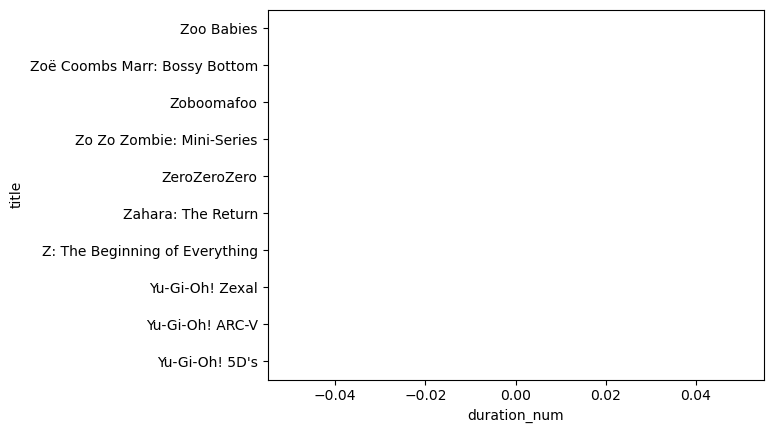

In [225]:
sns.barplot(data=df_tv_shows.sort_values(by="duration_num",ascending=False).head(10), y="title", x="duration_num",orient="horizontal")

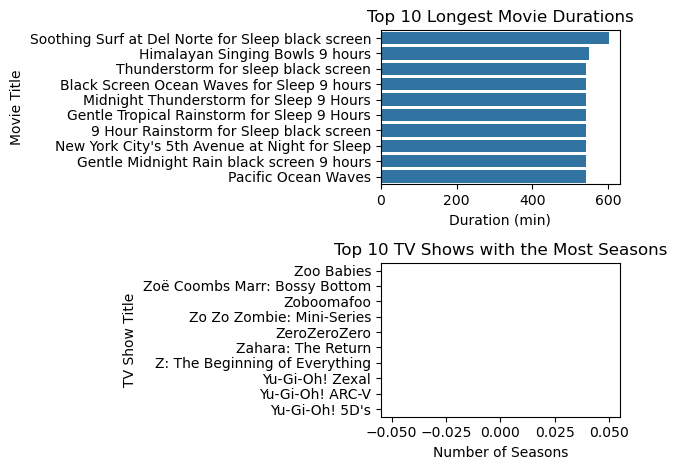

In [226]:
plt.subplot(2, 1, 1)
sns.barplot(data=df_movies.sort_values(by='duration_num',
                                       ascending=False).head(10), y='title', x='duration_num', 
            orient='horizontal')
plt.title('Top 10 Longest Movie Durations')
plt.xlabel('Duration (min)')
plt.ylabel('Movie Title')

# Subplot 2: Top 10 TV Shows with the Most Seasons
plt.subplot(2, 1, 2)
sns.barplot(data=df_tv_shows.sort_values(by='duration_num', ascending=False).head(10),
            y='title', 
            x='duration_num', orient='horizontal')
plt.title('Top 10 TV Shows with the Most Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('TV Show Title')

plt.tight_layout()
plt.show()